# Gaussian Mixture Models (GMM) — From Scratch + Comparison with k-means + Digits Generation

This notebook combines:
- **MML-book GMM tutorial & solution** — theoretical EM derivation and from-scratch implementation
- **Python Data Science Handbook** (Jake VanderPlas) — visual exploration, k-means vs GMM comparison, and generative modeling

We will:
1. Implement GMM using EM algorithm **from scratch**
2. Fit it to a **non-spherical 2D dataset** for better visualization
3. Compare to **k-means**
4. Apply GMMs for **digit clustering and generation**


## Learning goals
After this tutorial you should be able to:
- Understand the EM algorithm for Gaussian Mixture Models
- Implement E-step and M-step manually
- Visualize how GMM generalizes k-means
- Use GMM to model digits as a generative model


In [6]:
# PACKAGE: DO NOT EDIT
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, load_digits
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture

plt.rcParams['figure.figsize'] = (6, 4)


## 1. Synthetic 2D Dataset with Non-Spherical Clusters

We'll create a toy dataset and apply a random linear transformation to make clusters **elongated and rotated**.  
This helps visualize the difference between **k-means** (spherical clusters) and **GMM** (elliptical clusters).


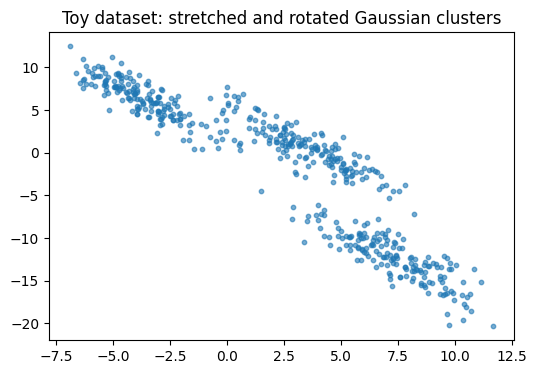

In [7]:
# Create isotropic blobs
rng = np.random.default_rng(13)
X, y_true = make_blobs(
    n_samples=500,
    centers=[(-2, 0), (0, 4), (4, 0)],
    cluster_std=[0.8, 0.9, 1.0],
    random_state=0
)

# Stretch and rotate using random matrix
X_stretched = np.dot(X, rng.standard_normal((2, 2)))

plt.scatter(X_stretched[:, 0], X_stretched[:, 1], s=10, alpha=0.6)
plt.title("Toy dataset: stretched and rotated Gaussian clusters")
plt.show()


In [14]:
def init_gmm_params(X, n_components, random_state=0):
    """Initialize means, covariances, and weights."""
    # TODO: initialize GMM parameters (means from data, identity covariances, uniform weights)
    #raise NotImplementedError
    # Перетвор. вхідні дані у float64 для запобіг. втрати точності при онов. параметрів
    X = np.asarray(X, dtype=np.float64)
    if X.ndim == 1:
        X = X.reshape(-1, 1)

    n_samples, n_features = X.shape

    # Перевір. коректність кількості кластерів
    if n_components <= 0 or n_components > n_samples:
        raise ValueError("n_components має бути в межах від 1 до кількості зразків")

    # Використ. локальн. генератор для відтворюваності тестів без впливу на глобальн. стан
    rng = np.random.default_rng(random_state)

    # Обираємо випадкові початкові центри з наших даних без повторень та створюємо копію
    indices = rng.choice(n_samples, size=n_components, replace=False)
    means = X[indices].copy()

    # Ініціаліз. одиничні матриці коваріацій форми (n_components, n_features, n_features)
    # np.broadcast_to() - віртуально "розтягує" масив до вказаної тривимірної форми без копіювання
    covariances = np.broadcast_to(
        np.eye(n_features, dtype=np.float64),
        (n_components, n_features, n_features)
    ).copy()

    # Задаємо однакові початкові ваги для всіх кластерів
    weights = np.full(n_components, 1.0/n_components, dtype=np.float64)

    return weights, means, covariances

In [15]:
def log_gaussian_pdf(X, mean, cov):
    """Compute log N(x|mean,cov) for each x."""
    # TODO: use np.linalg.slogdet or np.linalg.cholesky for stability
    #raise NotImplementedError
    # Перетвор. вхідні дані у float64 для точності обчислень
    X = np.asarray(X, dtype=np.float64)
    mean = np.asarray(mean, dtype=np.float64).ravel()
    cov = np.asarray(cov, dtype=np.float64)

    n_features = mean.shape[0]

    # Перевірка від одновимірн. вхідних масивів (наприклад, одна точка або 1 ознака)
    if X.ndim == 1:
        X = X.reshape(1, -1) if n_features > 1 else X.reshape(-1, 1)
    cov = cov.reshape(n_features, n_features)

    # Обчислюємо знак та логарифм визначника через slogdet для захисту від переповнення
    sign, logdet = np.linalg.slogdet(cov)

    # Якщо матриця коваріацій вироджена, додаємо малу регуляризац. на діагональ
    if sign <= 0 or not np.isfinite(logdet):
        cov = cov + 1e-6 * np.eye(n_features, dtype=np.float64)
        sign, logdet = np.linalg.slogdet(cov)

    # Центруємо точки навколо середнього
    diff = X - mean

    # Розв'яз. лін. систему cov @ Y = diff.T замість явного обернення матриці
    solved = np.linalg.solve(cov, diff.T)

    # Рахуємо квадратич. форму (відстань Махаланобіса) для кожної точки
    # Тобто рахуємо скалярний добуток (x - mean)^T * cov^(-1) * (x - mean) одразу для всіх точок
    # (не через np.linalg.inv бо може не спрацюв. на погано обумовл. матрицях + нам не потрібна велика рез. матриця N*N, а тыльки її діаг.)
    mahalanobis = np.sum(diff.T * solved, axis=0)

    # Збираємо наш підсумковий логарифм щільності норм. розподілу
    const_term = n_features * np.log(2.0 * np.pi)
    return -0.5 * (const_term + logdet + mahalanobis)

In [16]:
def e_step(X, pi, means, covs):
    """E-step: compute responsibilities and the current log-likelihood.

    Returns:
        gamma: array (n_samples, n_components), rows summing to 1.
        log_likelihood: float, sum over samples of log p(x_n).
    """
    # TODO: compute weighted log-probabilities, normalize using log-sum-exp
    #raise NotImplementedError
    # Перетвор. вхідні дані у float64 та перевіряємо форму масиву X
    X = np.asarray(X, dtype=np.float64)
    if X.ndim == 1:
        X = X.reshape(-1, 1)

    pi = np.asarray(pi, dtype=np.float64).ravel()
    means = np.asarray(means, dtype=np.float64)
    covs = np.asarray(covs, dtype=np.float64)

    n_samples = X.shape[0]
    n_components = pi.shape[0]

    # "Захищ." ваги від нуля перед логарифмуванням, щоб уникнути -inf або NaN
    log_pi = np.log(np.clip(pi, 1e-300, None))

    # Рахуємо логарифм щільності з урахуванням ваги кожного кластера
    weighted_log_prob = np.empty((n_samples, n_components),dtype=np.float64)
    for k in range(n_components):
        weighted_log_prob[:, k] =log_pi[k] +log_gaussian_pdf(X, means[k], covs[k])

    # Віднімаємо максимум по рядку перед exp (log-sum-exp), щоб уникнути переповнення чи нуля
    max_log = np.max(weighted_log_prob, axis=1, keepdims=True)
    log_prob_norm = max_log + np.log(
        np.sum(np.exp(weighted_log_prob - max_log), axis=1, keepdims=True)
    )

    # Переходимо від логарифмів до ймовірностей належності точок кластерам (gamma)
    gamma = np.exp(weighted_log_prob - log_prob_norm)

    # Додатково нормуємо рядки, щоб їх сума точно дорівнювала 1.0 попри похибку float
    gamma /= np.sum(gamma, axis=1, keepdims=True)

    # Рахуємо загальний логарифм вірогідності (log_likelihood) як звичайний float
    log_likelihood = float(np.sum(log_prob_norm))

    return gamma, log_likelihood

In [17]:
def m_step(X, gamma, reg_covar=1e-6):
    """M-step: update pi, means, and covariances."""
    # TODO: implement mean/cov updates
    #raise NotImplementedError
    # Перетвор. вхідні дані у float64 та перевіряємо форму масивів
    X = np.asarray(X, dtype=np.float64)
    if X.ndim == 1:
        X = X.reshape(-1, 1)

    gamma = np.asarray(gamma, dtype=np.float64)
    if gamma.ndim == 1:
        gamma = gamma.reshape(-1, 1)

    n_samples, n_features = X.shape
    n_components = gamma.shape[1]

    # Рахуємо ефективну кількість точок (суму ймовірностей) у кожному кластері
    nk = np.sum(gamma, axis=0)

    # Оновлюємо ваги кластерів і нормуємо їх, щоб у сумі вийшло 1
    pi = nk / n_samples
    pi_sum = np.sum(pi)
    if pi_sum > 0:
        pi /= pi_sum

    means = np.zeros((n_components, n_features), dtype=np.float64)
    covs = np.zeros((n_components, n_features, n_features), dtype=np.float64)
    eye = np.eye(n_features, dtype=np.float64)

    for k in range(n_components):
        # Захист від ділення на нуль, якщо кластер не отримав жодної точки
        if nk[k]< 1e-12:
            covs[k] = eye.copy()
            continue

        # Оновлюємо центр кластера як зважене середнє всіх точок
        means[k] = np.sum(gamma[:, k: k + 1] *X, axis=0) /nk[k]

        # Рахуємо зважену матрицю коваріацій для поточного кластера
        diff = X - means[k]
        weighted_diff = gamma[:, k : k + 1] * diff
        cov = (weighted_diff.T @ diff) / nk[k]

        # Вирівн. похибку округлення (робимо матрицю точно симетричною) і додаємо регуляризацію
        cov = 0.5 * (cov + cov.T) + reg_covar * eye
        covs[k] = cov

    return pi, means, covs

In [18]:
# SELF-CHECK - run this once init_gmm_params, log_gaussian_pdf, e_step and m_step
# are implemented (before writing the EM loop).
pi_chk, means_chk, covs_chk = init_gmm_params(X_stretched, 3, random_state=0)
gamma_chk, ll_chk = e_step(X_stretched, pi_chk, means_chk, covs_chk)

assert gamma_chk.shape == (X_stretched.shape[0], 3), "responsibilities are (n_samples, n_components)"
assert np.allclose(gamma_chk.sum(axis=1), 1.0), "each point's responsibilities must sum to 1"
assert np.all(gamma_chk >= -1e-12), "responsibilities are probabilities"
assert np.ndim(ll_chk) == 0, "e_step must also return the scalar log-likelihood"

pi_new, means_new, covs_new = m_step(X_stretched, gamma_chk)
assert np.isclose(pi_new.sum(), 1.0), "mixture weights must sum to 1"
assert np.all(np.linalg.eigvalsh(covs_new) > 0), "every covariance must stay positive definite"

print("GMM self-check passed")

GMM self-check passed


In [19]:
def gmm_em(X, n_components, max_iter=100, tol=1e-4, random_state=0):
    """Run EM algorithm for GMM."""
    # TODO: combine steps into EM loop (initialize → alternate E and M → stop on convergence)
    #raise NotImplementedError
    # Ініціалізуємо початкові ваги, центри та матриці коваріацій
    pi, means, covs = init_gmm_params(X, n_components, random_state=random_state)

    log_likelihoods = []
    prev_ll = None

    for _ in range(max_iter):
        # E-крок: рахуємо ймовірності належності точок та поточний log-likelihood (якість моделі)
        gamma, ll = e_step(X, pi, means, covs)
        log_likelihoods.append(ll)

        # Перевір., що не перша ітерація циклу + перевіряємо збіжність: якщо приріст log-likelihood менший за tol, зупиняємо цикл
        if prev_ll is not None and abs(ll - prev_ll) < tol:
            break

        prev_ll = ll

        # M-крок: оновлюємо ваги, центри та коваріації кластерів
        pi, means, covs = m_step(X, gamma)

    return pi, means, covs, log_likelihoods

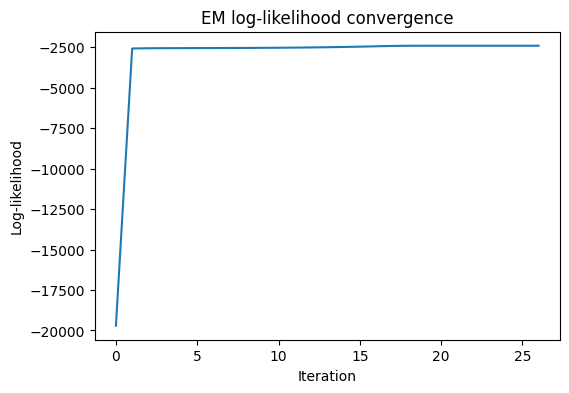

In [20]:
# Fit your GMM from scratch on the stretched dataset
K = 3
pi_hat, means_hat, covs_hat, ll = gmm_em(X_stretched, n_components=K, random_state=0)

plt.plot(ll)
plt.title("EM log-likelihood convergence")
plt.xlabel("Iteration")
plt.ylabel("Log-likelihood")
plt.show()


## 2. Compare GMM vs k-means

Use your GMM implementation and sklearn's k-means to see how they differ on the **stretched data**.


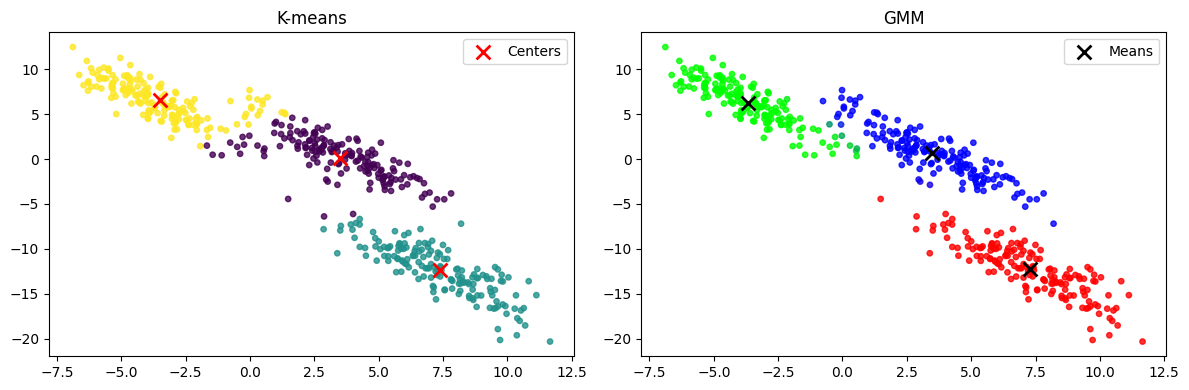

In [21]:
# TODO: fit k-means (n_clusters=3) and plot vs GMM responsibilities
#raise NotImplementedError
# Навчаємо K-means для кластеризації саме на 3 кластери
kmeans = KMeans(n_clusters=3, n_init=10, random_state=0)
kmeans_labels = kmeans.fit_predict(X_stretched)

# Отримуємо матрицю ймовірностей (GMM responsibilities) для навченої GMM
gamma_hat, _ = e_step(X_stretched, pi_hat, means_hat, covs_hat)

# Будуємо два графіки для порівняння
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Графік 1: результат K-means ("ріже" простір сферами без урахування витягнут.)
axes[0].scatter(X_stretched[:, 0], X_stretched[:, 1], c=kmeans_labels, s=15, alpha=0.8)
axes[0].scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    c="red",
    marker="x",
    s=100,
    linewidths=2,
    label="Centers",
)
axes[0].set_title("K-means")
axes[0].legend()

# Графік 2: результат GMM (колір RGB показує ймовірність належності до кожного з 3 кластерів)
axes[1].scatter(
    X_stretched[:, 0],
    X_stretched[:, 1],
    c=np.clip(gamma_hat, 0.0, 1.0),
    s=15,
    alpha=0.8,
)
axes[1].scatter(
    means_hat[:, 0],
    means_hat[:, 1],
    c="black",
    marker="x",
    s=100,
    linewidths=2,
    label="Means",
)
axes[1].set_title("GMM")
axes[1].legend()

plt.tight_layout()
plt.show()


## 3. GMM on Digits Dataset

Now let's move from 2D toy data to a higher-dimensional example.

We'll use the `digits` dataset to:
- fit GMMs to 10 components
- visualize learned component means as prototypical digits
- sample new synthetic digits


In [22]:
digits = load_digits()
X_digits = digits.data
images = digits.images
print("Digits shape:", X_digits.shape)


Digits shape: (1797, 64)


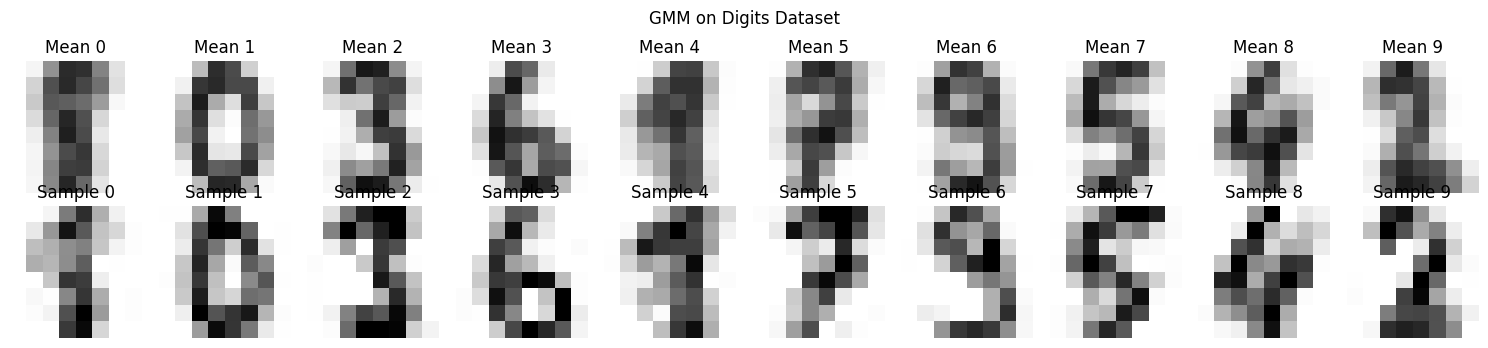

In [43]:
# TODO: Fit GaussianMixture from sklearn and visualize its means and generated samples
#raise NotImplementedError
# Навчаємо GMM на 10 компонентів із регуляризац. коваріацій для стабільності у 64-вимірному просторі
gmm_digits = GaussianMixture(
    n_components=10,
    covariance_type="full",
    reg_covar=1e-2,
    n_init=30,
    max_iter=600,
    random_state=42,
)
gmm_digits.fit(X_digits)

# Генеруємо по 1 прикладу конкретно з кожного кластера i (щоб Sample i відповідав Mean i)
rng = np.random.default_rng(42)
# Генеруємо випадковий вектор (rng.multivariate_normal) із багатовимірн. норм. розподілу із середнім means_[i] та коваріацією covariances_[i]
samples = np.array([
    rng.multivariate_normal(gmm_digits.means_[i], gmm_digits.covariances_[i])
    for i in range(10)
])
samples = np.clip(samples, 0.0, 16.0)

# Зверху середні (прототипи), знизу - згенеровані цифри
fig, axes = plt.subplots(2, 10, figsize=(15, 3.5))

for i in range(10):
    axes[0, i].imshow(gmm_digits.means_[i].reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
    axes[0, i].set_title(f"Mean {i}")
    axes[0, i].axis("off")

    axes[1, i].imshow(samples[i].reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
    axes[1, i].set_title(f"Sample {i}")
    axes[1, i].axis("off")

plt.suptitle("GMM on Digits Dataset")
plt.tight_layout()
plt.show()

## 4. Reflection

In your own words:
- What is the main difference between k-means and GMM?
- Why does GMM handle elongated clusters better?
- How does GMM act as a **generative** model?


1. У чому головна різниця між k-means та GMM?
- K-means виконує "жорстку" кластеризацію: кожна точка суворо належить лише до одного найближчого центру за евклідовою відстанню.
- GMM виконує більш "м'яку" ймовірнісну кластеризацію: замість однієї мітки модель обчислює для кожної точки вектор імовірностей γ_nk належності до всіх кластерів одночасно.

2. Чому GMM краще працює з витягнутими кластерами?

K-means використов. звичайну евклідову відстань, тому неявно вважає всі кластери округ. (сферичними). Через це на (лівий, пунтк k-means vs GMM) графіку він помилково розрізає верхній лівий кластер впоперек і відносить його правий край (в районі x [-1, 1]) до центрального фіолетового кластера.

GMM для кожного кластера оцінює власну матрицю коваріацій (∑_k), яка враховує напрямок нахилу та ступінь розтягування наших даних. Завдяки цьому на правому графіку модель підлаштовує еліпси під наближену форму хмар і більш. коректн. розділяє всі три витягнуті кластери.

3. Як GMM працює як генеративна модель?

Після навчання GMM зберігає параметри розподілу для кожного кластера: його вагу, середній вектор (прототип цифри див. у верхньому ряду) та матрицю коваріацій, яка описує розкид значень пікселів.

Щоб згенерувати новий об'єкт, модель робить 2 кроки: спочатку випадково обирається кластер відповідно до його ваги, а потім із його нормального розподілу випадковим чином генерується нова точка. У нашому завданні було згенеровано по одному зразку з розподілу кожного кластера за допомогою multivariate_normal, тому в нижньому ряду під кожним прототипом Mean i з'явився новий згенерований приклад Sample i.
